In [1]:
# Wumpus World Agent using Propositional Logic (function-based version)
# cells are (x, y): x = column, y = row, (1,1) = bottom-left start cell
from collections import deque
import random
import itertools

In [2]:
# PART 1 - The World (grid). A world is a plain dict.
def neighbors(n, x, y):
    # the (up to 4) cells directly adjacent to (x, y) inside an n x n grid
    cand = [(x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)]
    return [(a, b) for a, b in cand if 1 <= a <= n and 1 <= b <= n]


def make_world(size, wumpus, pits, gold):
    assert (1, 1) not in pits and (1, 1) != wumpus, "start cell must be safe"
    assert gold != wumpus and gold not in pits, "gold cannot be in a hazard"
    return {"n": size, "wumpus": wumpus, "pits": set(pits), "gold": gold}


def is_deadly(world, cell):
    return cell == world["wumpus"] or cell in world["pits"]


def show_world(world, title="TRUE WORLD (hidden from the agent)"):
    n = world["n"]
    print(title)
    for y in range(n, 0, -1):                                # top row first
        row = ""
        for x in range(1, n + 1):
            c = (x, y)
            sym = "W" if c == world["wumpus"] else "P" if c in world["pits"] else "G" if c == world["gold"] else "."
            row += f" {sym} |"
        print(f"y={y} |{row}")
    print("     " + "".join(f" x={x} " for x in range(1, n + 1)))
    print("(W=Wumpus  P=Pit  G=Gold  .=empty)")

In [3]:
demo_world = make_world(size=4, wumpus=(3, 1), pits={(1, 3), (4, 3), (3, 4)}, gold=(3, 2))
show_world(demo_world)
print("Neighbours of (3,3):", neighbors(4, 3, 3))
print("Neighbours of (4,1):", neighbors(4, 4, 1))

TRUE WORLD (hidden from the agent)
y=4 | . | . | P | . |
y=3 | P | . | . | P |
y=2 | . | . | G | . |
y=1 | . | . | W | . |
      x=1  x=2  x=3  x=4 
(W=Wumpus  P=Pit  G=Gold  .=empty)
Neighbours of (3,3): [(4, 3), (2, 3), (3, 4), (3, 2)]
Neighbours of (4,1): [(3, 1), (4, 2)]


In [4]:
# PART 2 - Percept generator
def percept(world, cell):
    x, y = cell
    adj = neighbors(world["n"], x, y)
    return {
        "stench":  any(a == world["wumpus"] for a in adj),
        "breeze":  any(a in world["pits"] for a in adj),
        "glitter": cell == world["gold"],
    }

for c in [(1, 1), (2, 1), (1, 2), (3, 2)]:
    print(c, percept(demo_world, c))

(1, 1) {'stench': False, 'breeze': False, 'glitter': False}
(2, 1) {'stench': True, 'breeze': False, 'glitter': False}
(1, 2) {'stench': False, 'breeze': True, 'glitter': False}
(3, 2) {'stench': True, 'breeze': False, 'glitter': True}


In [5]:
# PART 3 - Propositional symbols and connectives
# A symbol is a string such as "P(1,2)"; compound sentences are tuples:
#   ("not", a)   ("and", a, b, ...)   ("or", a, b, ...)   ("=>", a, b)   ("<=>", a, b)
def Not(a):        return ("not", a)
def And(*args):    return ("and",) + args
def Or(*args):     return ("or",) + args
def Implies(a, b): return ("=>", a, b)
def Iff(a, b):     return ("<=>", a, b)

def P(x, y): return f"P({x},{y})"      # pit in (x,y)
def W(x, y): return f"W({x},{y})"      # wumpus in (x,y)
def B(x, y): return f"B({x},{y})"      # breeze felt in (x,y)
def S(x, y): return f"S({x},{y})"      # stench smelled in (x,y)

def OR(items):  return items[0] if len(items) == 1 else Or(*items)
def AND(items): return items[0] if len(items) == 1 else And(*items)


def to_str(e):
    if isinstance(e, str): return e
    op, args = e[0], e[1:]
    if op == "not": return f"~{to_str(args[0])}"
    if op == "and": return "(" + " & ".join(map(to_str, args)) + ")"
    if op == "or":  return "(" + " | ".join(map(to_str, args)) + ")"
    if op == "=>":  return f"({to_str(args[0])} => {to_str(args[1])})"
    if op == "<=>": return f"({to_str(args[0])} <=> {to_str(args[1])})"


def evaluate(e, model):
    # truth value of sentence e under model (dict symbol -> bool)
    if isinstance(e, str): return model[e]
    op, args = e[0], e[1:]
    if op == "not": return not evaluate(args[0], model)
    if op == "and": return all(evaluate(a, model) for a in args)
    if op == "or":  return any(evaluate(a, model) for a in args)
    if op == "=>":  return (not evaluate(args[0], model)) or evaluate(args[1], model)
    if op == "<=>": return evaluate(args[0], model) == evaluate(args[1], model)


def symbols(e):
    if isinstance(e, str): return {e}
    return set().union(*[symbols(a) for a in e[1:]])


def truth_table(expr):
    syms = sorted(symbols(expr))
    print(" | ".join(f"{s:7}" for s in syms) + " || " + to_str(expr))
    for vals in itertools.product([False, True], repeat=len(syms)):
        m = dict(zip(syms, vals))
        print(" | ".join(f"{str(v):7}" for v in vals) + " || " + str(evaluate(expr, m)))

In [6]:
# stench rule for corner cell (4,1) of a 4x4 grid: its neighbours are (3,1) and (4,2)
rule = Iff(S(4, 1), Or(W(3, 1), W(4, 2)))
print("Rule:", to_str(rule), "\n")
truth_table(rule)

print("\nImplication  Wumpus at (3,1) => Stench at (4,1):")
truth_table(Implies(W(3, 1), S(4, 1)))

print("\nAND / NOT  ~B(2,2) & ~S(2,2)  (a completely quiet cell):")
truth_table(And(Not(B(2, 2)), Not(S(2, 2))))

Rule: (S(4,1) <=> (W(3,1) | W(4,2))) 

S(4,1)  | W(3,1)  | W(4,2)  || (S(4,1) <=> (W(3,1) | W(4,2)))
False   | False   | False   || True
False   | False   | True    || False
False   | True    | False   || False
False   | True    | True    || False
True    | False   | False   || False
True    | False   | True    || True
True    | True    | False   || True
True    | True    | True    || True

Implication  Wumpus at (3,1) => Stench at (4,1):
S(4,1)  | W(3,1)  || (W(3,1) => S(4,1))
False   | False   || True
False   | True    || False
True    | False   || True
True    | True    || True

AND / NOT  ~B(2,2) & ~S(2,2)  (a completely quiet cell):
B(2,2)  | S(2,2)  || (~B(2,2) & ~S(2,2))
False   | False   || True
False   | True    || False
True    | False   || False
True    | True    || False


In [7]:
# PART 4 - CNF converter. A literal is "P(1,2)" or "~P(1,2)"; a clause is a frozenset of literals.
def neg(lit):                                   # negate a literal string
    return lit[1:] if lit.startswith("~") else "~" + lit

def remove_implications(e):                     # a<=>b -> (~a|b)&(~b|a),  a=>b -> ~a|b
    if isinstance(e, str): return e
    op, args = e[0], [remove_implications(a) for a in e[1:]]
    if op == "=>":  return Or(Not(args[0]), args[1])
    if op == "<=>": return And(Or(Not(args[0]), args[1]), Or(Not(args[1]), args[0]))
    return (op,) + tuple(args)

def push_not(e, negate=False):                  # De Morgan -> negation normal form
    if isinstance(e, str): return Not(e) if negate else e
    op, args = e[0], e[1:]
    if op == "not": return push_not(args[0], not negate)
    parts = [push_not(a, negate) for a in args]
    if op == "and": return Or(*parts) if negate else And(*parts)
    if op == "or":  return And(*parts) if negate else Or(*parts)

def distribute(e):                              # OR over AND -> list of clauses
    if isinstance(e, str): return [frozenset([e])]
    op, args = e[0], e[1:]
    if op == "not": return [frozenset(["~" + args[0]])]
    if op == "and": return [c for a in args for c in distribute(a)]
    if op == "or":
        result = [frozenset()]
        for a in args:
            result = [c | d for c in result for d in distribute(a)]
        return result

def to_cnf(expr):
    clauses = distribute(push_not(remove_implications(expr)))
    return [c for c in clauses if not any(neg(l) in c for l in c)]   # drop tautologies (A | ~A)

def show_clauses(clauses):
    for c in clauses:
        print("  ", " | ".join(sorted(c)) if c else "(empty clause = contradiction)")

In [8]:
print("Original :", to_str(rule))
print("CNF clauses:")
show_clauses(to_cnf(rule))

r2 = Implies(And(B(1, 2), Not(P(1, 3))), Or(P(2, 2), P(1, 1)))
print("\nOriginal :", to_str(r2))
print("CNF clauses:")
show_clauses(to_cnf(r2))

Original : (S(4,1) <=> (W(3,1) | W(4,2)))
CNF clauses:
   W(3,1) | W(4,2) | ~S(4,1)
   S(4,1) | ~W(3,1)
   S(4,1) | ~W(4,2)

Original : ((B(1,2) & ~P(1,3)) => (P(2,2) | P(1,1)))
CNF clauses:
   P(1,1) | P(1,3) | P(2,2) | ~B(1,2)


In [9]:
# PART 5 - Inference engine: DPLL + entailment by refutation (KB |= q  iff  KB & ~q is unsatisfiable)
def assign(clauses, lit):
    # make `lit` true: drop clauses it satisfies, delete ~lit from the others
    return [c - {neg(lit)} for c in clauses if lit not in c]

def dpll(clauses):
    if not clauses: return True                         # nothing left to satisfy
    if any(len(c) == 0 for c in clauses): return False   # empty clause: contradiction
    for c in clauses:                                    # unit propagation
        if len(c) == 1:
            return dpll(assign(clauses, next(iter(c))))
    lit = next(iter(clauses[0]))                         # otherwise guess
    return dpll(assign(clauses, lit)) or dpll(assign(clauses, neg(lit)))

def entails(clauses, lit):
    return not dpll(list(clauses) + [frozenset([neg(lit)])])

In [10]:
# Stench at (4,1), and the Wumpus is NOT at (4,2)  =>  it must be at (3,1)
kb_demo = to_cnf(rule) + [frozenset(["S(4,1)"]), frozenset(["~W(4,2)"])]
print("KB |= W(3,1)  ?", entails(kb_demo, "W(3,1)"))
print("KB |= ~W(3,1) ?", entails(kb_demo, "~W(3,1)"))
print("KB |= W(4,2)  ?", entails(kb_demo, "W(4,2)"), "(false - the KB says the opposite)")
kb_demo2 = to_cnf(rule) + [frozenset(["~S(4,1)"])]
print("No stench at (4,1): KB |= ~W(3,1)?", entails(kb_demo2, "~W(3,1)"), "| KB |= ~W(4,2)?", entails(kb_demo2, "~W(4,2)"), " -> both safe from the Wumpus")
kb_demo3 = to_cnf(rule) + [frozenset(["S(4,1)"])]
print("Only stench known : KB |= W(3,1)?", entails(kb_demo3, "W(3,1)"), "| KB |= ~W(3,1)?", entails(kb_demo3, "~W(3,1)"), " -> unknown!")

KB |= W(3,1)  ? True
KB |= ~W(3,1) ? False
KB |= W(4,2)  ? False (false - the KB says the opposite)
No stench at (4,1): KB |= ~W(3,1)? True | KB |= ~W(4,2)? True  -> both safe from the Wumpus
Only stench known : KB |= W(3,1)? False | KB |= ~W(3,1)? False  -> unknown!


In [11]:
# PART 6 - Knowledge Base (a dict) with the rules ("physics") of the Wumpus world
def make_kb(n):
    kb = {"n": n, "clauses": set(), "rules": [], "queries": 0}
    add_world_rules(kb)
    return kb

def tell(kb, sentence):
    kb["rules"].append(sentence)
    kb["clauses"].update(to_cnf(sentence))

def ask(kb, lit):                                   # is `lit` entailed by the KB ?
    kb["queries"] += 1
    return entails(kb["clauses"], lit)

def add_world_rules(kb):
    n = kb["n"]
    cells = [(x, y) for x in range(1, n + 1) for y in range(1, n + 1)]
    for (x, y) in cells:
        adj = neighbors(n, x, y)
        tell(kb, Iff(B(x, y), OR([P(a, b) for a, b in adj])))   # breeze rule
        tell(kb, Iff(S(x, y), OR([W(a, b) for a, b in adj])))   # stench rule
    tell(kb, Not(P(1, 1)))
    tell(kb, Not(W(1, 1)))
    tell(kb, OR([W(x, y) for x, y in cells]))                   # at least one Wumpus
    for c1, c2 in itertools.combinations(cells, 2):             # at most one Wumpus
        tell(kb, Or(Not(W(*c1)), Not(W(*c2))))

In [12]:
kb_show = make_kb(4)
print("Number of rules told      :", len(kb_show["rules"]))
print("Number of CNF clauses     :", len(kb_show["clauses"]))
print("\nSome of the rules written in propositional logic:")
for r in kb_show["rules"][10:14] + kb_show["rules"][32:35]:
    print("  ", to_str(r))
print("\nBefore any percept, is (1,2) provably safe?  KB |= ~P(1,2):", ask(kb_show, "~P(1,2)"))

Number of rules told      : 155
Number of CNF clauses     : 251

Some of the rules written in propositional logic:
   (B(2,2) <=> (P(3,2) | P(1,2) | P(2,3) | P(2,1)))
   (S(2,2) <=> (W(3,2) | W(1,2) | W(2,3) | W(2,1)))
   (B(2,3) <=> (P(3,3) | P(1,3) | P(2,4) | P(2,2)))
   (S(2,3) <=> (W(3,3) | W(1,3) | W(2,4) | W(2,2)))
   ~P(1,1)
   ~W(1,1)
   (W(1,1) | W(1,2) | W(1,3) | W(1,4) | W(2,1) | W(2,2) | W(2,3) | W(2,4) | W(3,1) | W(3,2) | W(3,3) | W(3,4) | W(4,1) | W(4,2) | W(4,3) | W(4,4))

Before any percept, is (1,2) provably safe?  KB |= ~P(1,2): False


In [13]:
# PART 7 - Reasoner: TELL percepts, ASK about safety. State is a dict.
def make_reasoner(n):
    return {"n": n, "kb": make_kb(n), "visited": set(), "safe": {(1, 1)},
            "pits": set(), "wumpus": None}

def tell_percepts(r, cell, pc):
    x, y = cell
    r["visited"].add(cell)
    r["safe"].add(cell)
    tell(r["kb"], Not(P(x, y)))                                  # we are alive here
    tell(r["kb"], Not(W(x, y)))
    tell(r["kb"], B(x, y) if pc["breeze"] else Not(B(x, y)))
    tell(r["kb"], S(x, y) if pc["stench"] else Not(S(x, y)))

def infer(r):
    # ASK the KB about every cell; return what was newly discovered
    kb, new_safe, new_pits, new_wumpus = r["kb"], [], [], []
    for x in range(1, r["n"] + 1):
        for y in range(1, r["n"] + 1):
            c = (x, y)
            if c not in r["safe"]:
                if ask(kb, f"~P({x},{y})") and ask(kb, f"~W({x},{y})"):
                    r["safe"].add(c); new_safe.append(c)
            if c not in r["pits"] and c not in r["safe"]:
                if ask(kb, f"P({x},{y})"):
                    r["pits"].add(c); new_pits.append(c)
            if r["wumpus"] is None and c not in r["safe"]:
                if ask(kb, f"W({x},{y})"):
                    r["wumpus"] = c; new_wumpus.append(c)
    return new_safe, new_pits, new_wumpus

In [14]:
# replay the first moves by hand and watch the conclusions appear
r = make_reasoner(4)
for cell in [(1, 1), (2, 1), (1, 2)]:
    pc = percept(demo_world, cell)
    tell_percepts(r, cell, pc)
    print(f"At {cell} percept = {pc}")
    print("  newly proven safe / pits / wumpus:", infer(r), "\n")
print("=> (2,1) smelled a stench and (1,2) did not, so the Wumpus is (3,1), not (2,2);")
print("   (1,2) felt a breeze and (2,1) did not, so the pit must be (1,3).")

At (1, 1) percept = {'stench': False, 'breeze': False, 'glitter': False}


  newly proven safe / pits / wumpus:

 ([(1, 2), (2, 1)], [], []) 

At (2, 1) percept = {'stench': True, 'breeze': False, 'glitter': False}


  newly proven safe / pits / wumpus: ([], [], []) 

At (1, 2) percept = {'stench': False, 'breeze': True, 'glitter': False}
  newly proven safe / pits / wumpus: ([(2, 2)], [(1, 3)], [(3, 1)]) 

=> (2,1) smelled a stench and (1,2) did not, so the Wumpus is (3,1), not (2,2);
   (1,2) felt a breeze and (2,1) did not, so the pit must be (1,3).


In [15]:
# PART 8 - Planner: BFS over proven-safe cells
def find_path(n, start, safe, is_goal):
    queue, seen = deque([[start]]), {start}
    while queue:
        path = queue.popleft()
        if len(path) > 1 and is_goal(path[-1]):
            return path
        for nb in neighbors(n, *path[-1]):
            if nb in safe and nb not in seen:
                seen.add(nb)
                queue.append(path + [nb])
    return None

def next_exploration_path(r, pos):
    # shortest safe path to the nearest safe cell that has not been visited
    return find_path(r["n"], pos, r["safe"], lambda c: c not in r["visited"])

def path_home(r, pos):
    if pos == (1, 1): return [pos]
    return find_path(r["n"], pos, r["safe"], lambda c: c == (1, 1))

In [16]:
print("Using the reasoner from Part 7 (agent has visited (1,1),(2,1),(1,2)):")
print("  safe cells  :", sorted(r["safe"]))
print("  visited     :", sorted(r["visited"]))
print("  next target path from (1,2):", next_exploration_path(r, (1, 2)))
print("  route home from (1,2)      :", path_home(r, (1, 2)))

Using the reasoner from Part 7 (agent has visited (1,1),(2,1),(1,2)):
  safe cells  : [(1, 1), (1, 2), (2, 1), (2, 2)]
  visited     : [(1, 1), (1, 2), (2, 1)]
  next target path from (1,2): [(1, 2), (2, 2)]
  route home from (1,2)      : [(1, 2), (1, 1)]


In [17]:
# PART 9 - Agent loop: Sense -> Tell -> Infer -> Decide -> Act
# score: -1 per move, +1000 for climbing out with the gold, -1000 for dying
def make_agent(world, verbose=True):
    return {"world": world, "verbose": verbose, "brain": make_reasoner(world["n"]),
            "pos": (1, 1), "path": [(1, 1)], "has_gold": False,
            "status": "RUNNING", "step_no": 0}

def show_knowledge(agent):
    b, n = agent["brain"], agent["world"]["n"]
    for y in range(n, 0, -1):
        row = ""
        for x in range(1, n + 1):
            c = (x, y)
            s = "A" if c == agent["pos"] else "P" if c in b["pits"] else "W" if c == b["wumpus"] \
                else "v" if c in b["visited"] else "o" if c in b["safe"] else "?"
            row += f" {s} |"
        print(f"   y={y} |{row}")
    print("        " + "".join(f" x={x} " for x in range(1, n + 1)))
    print("   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)")

def arrive(agent):                                  # SENSE -> TELL -> INFER
    pc = percept(agent["world"], agent["pos"])
    tell_percepts(agent["brain"], agent["pos"], pc)
    new_safe, new_pits, new_w = infer(agent["brain"])
    seen = [k.capitalize() for k, v in pc.items() if v] or ["nothing"]
    if agent["verbose"]:
        print(f"\nStep {agent['step_no']}: at {agent['pos']}  percepts: {', '.join(seen)}")
        if new_safe: print("   inferred SAFE  :", new_safe)
        if new_pits: print("   inferred PIT   :", new_pits)
        if new_w:    print("   inferred WUMPUS:", new_w)
        show_knowledge(agent)
    if pc["glitter"]:
        agent["has_gold"] = True
        if agent["verbose"]: print("   *** GLITTER! Agent GRABS the gold ***")

def walk(agent, route):                             # ACT
    for cell in route[1:]:
        agent["pos"] = cell
        agent["path"].append(cell)
        if is_deadly(agent["world"], cell):
            agent["status"] = "DIED"
            return False
    return True

def run_agent(agent, max_steps=100):
    arrive(agent)
    while not agent["has_gold"] and agent["status"] == "RUNNING" and agent["step_no"] < max_steps:
        route = next_exploration_path(agent["brain"], agent["pos"])
        if route is None:
            agent["status"] = "STUCK"
            if agent["verbose"]: print("\nNo cell can be PROVEN safe -> the agent refuses to gamble and stops.")
            break
        agent["step_no"] += 1
        if agent["verbose"]: print(f"\n>> Decision: go {agent['pos']} -> {route[-1]} via {route}")
        if not walk(agent, route): break
        arrive(agent)
    if agent["has_gold"] and agent["status"] == "RUNNING":
        home = path_home(agent["brain"], agent["pos"])
        if agent["verbose"]: print(f"\n>> Gold in hand. Return route: {home}")
        walk(agent, home)
        agent["status"] = "WON"
    return result(agent)

def result(agent):
    moves = len(agent["path"]) - 1
    score = -moves + (1000 if agent["status"] == "WON" else -1000 if agent["status"] == "DIED" else 0)
    return {"status": agent["status"], "moves": moves, "score": score,
            "cells_explored": len(agent["brain"]["visited"]), "kb_queries": agent["brain"]["kb"]["queries"]}

In [18]:
# Demo 1 - full verbose run on the 4x4 demo world
show_world(demo_world)
agent = make_agent(demo_world, verbose=True)
res = run_agent(agent)

TRUE WORLD (hidden from the agent)
y=4 | . | . | P | . |
y=3 | P | . | . | P |
y=2 | . | . | G | . |
y=1 | . | . | W | . |
      x=1  x=2  x=3  x=4 
(W=Wumpus  P=Pit  G=Gold  .=empty)



Step 0: at (1, 1)  percepts: nothing
   inferred SAFE  : [(1, 2), (2, 1)]
   y=4 | ? | ? | ? | ? |
   y=3 | ? | ? | ? | ? |
   y=2 | o | ? | ? | ? |
   y=1 | A | o | ? | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)

>> Decision: go (1, 1) -> (2, 1) via [(1, 1), (2, 1)]



Step 1: at (2, 1)  percepts: Stench
   y=4 | ? | ? | ? | ? |
   y=3 | ? | ? | ? | ? |
   y=2 | o | ? | ? | ? |
   y=1 | v | A | ? | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)

>> Decision: go (2, 1) -> (1, 2) via [(2, 1), (1, 1), (1, 2)]



Step 2: at (1, 2)  percepts: Breeze
   inferred SAFE  : [(2, 2)]
   inferred PIT   : [(1, 3)]
   inferred WUMPUS: [(3, 1)]
   y=4 | ? | ? | ? | ? |
   y=3 | P | ? | ? | ? |
   y=2 | A | o | ? | ? |
   y=1 | v | v | W | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)

>> Decision: go (1, 2) -> (2, 2) via [(1, 2), (2, 2)]

Step 3: at (2, 2)  percepts: nothing
   inferred SAFE  : [(2, 3), (3, 2)]
   y=4 | ? | ? | ? | ? |
   y=3 | P | o | ? | ? |
   y=2 | v | A | o | ? |
   y=1 | v | v | W | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)

>> Decision: go (2, 2) -> (3, 2) via [(2, 2), (3, 2)]

Step 4: at (3, 2)  percepts: Stench, Glitter
   inferred SAFE  : [(3, 3), (4, 2)]
   y=4 | ? | ? | ? | ? |
   y=3 | P | o | o | ? |
   y=2 | v | v | A | o |
   y=1 | v | v | W | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)
   *** GLITTER! Agent GRAB

In [19]:
def show_final(agent):
    w, n = agent["world"], agent["world"]["n"]
    print("EXPLORATION PATH:")
    print("  " + " -> ".join(f"({x},{y})" for x, y in agent["path"]))
    order = {}
    for i, c in enumerate(agent["path"]):
        order.setdefault(c, i)                      # step at which each cell was first reached
    print("\nPATH MAP (number = step at which the cell was first reached):")
    for y in range(n, 0, -1):
        row = ""
        for x in range(1, n + 1):
            c = (x, y)
            tag = "W" if c == w["wumpus"] else "P" if c in w["pits"] else "G" if c == w["gold"] else " "
            step = str(order[c]) if c in order else "-"
            row += f" {step:>2}{tag}|"
        print(f"  y={y} |{row}")
    print("        " + "".join(f"  x={x} " for x in range(1, n + 1)))
    res = result(agent)
    print("\nFINAL RESULT:", {"WON": "Agent grabbed the gold and escaped alive!",
                              "STUCK": "Agent stopped: no provably safe move left.",
                              "DIED": "Agent died."}[res["status"]])
    for k, v in res.items(): print(f"  {k:15}: {v}")

show_final(agent)

EXPLORATION PATH:
  (1,1) -> (2,1) -> (1,1) -> (1,2) -> (2,2) -> (3,2) -> (2,2) -> (1,2) -> (1,1)

PATH MAP (number = step at which the cell was first reached):
  y=4 |  - |  - |  -P|  - |
  y=3 |  -P|  - |  - |  -P|
  y=2 |  3 |  4 |  5G|  - |
  y=1 |  0 |  1 |  -W|  - |
          x=1   x=2   x=3   x=4 

FINAL RESULT: Agent grabbed the gold and escaped alive!
  status         : WON
  moves          : 8
  score          : 992
  cells_explored : 5
  kb_queries     : 160


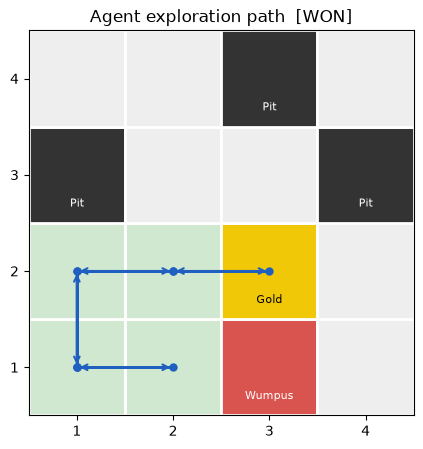

In [20]:
import matplotlib.pyplot as plt

def plot_path(agent, title="Agent exploration path"):
    w, n, path = agent["world"], agent["world"]["n"], agent["path"]
    fig, ax = plt.subplots(figsize=(5, 5))
    for x in range(1, n + 1):
        for y in range(1, n + 1):
            c = (x, y)
            color = "#d9534f" if c == w["wumpus"] else "#333333" if c in w["pits"] else "#f0c808" if c == w["gold"] \
                else "#cfe8cf" if c in agent["brain"]["visited"] else "#eeeeee"
            ax.add_patch(plt.Rectangle((x - .5, y - .5), 1, 1, facecolor=color, edgecolor="white", lw=2))
            label = "Wumpus" if c == w["wumpus"] else "Pit" if c in w["pits"] else "Gold" if c == w["gold"] else ""
            if label: ax.text(x, y - .3, label, ha="center", va="center", fontsize=8,
                              color="white" if c in w["pits"] or c == w["wumpus"] else "black")
    xs, ys = zip(*path)
    ax.plot(xs, ys, "-o", color="#1f5fbf", lw=2, ms=5)
    for i in range(len(path) - 1):
        (x0, y0), (x1, y1) = path[i], path[i + 1]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color="#1f5fbf", lw=1.5))
    ax.set_xlim(.5, n + .5); ax.set_ylim(.5, n + .5)
    ax.set_xticks(range(1, n + 1)); ax.set_yticks(range(1, n + 1))
    ax.set_title(f"{title}  [{agent['status']}]"); ax.set_aspect("equal")
    plt.show()

plot_path(agent)

In [21]:
# Demo 2 - step-by-step mode: call one_step() repeatedly to advance one decision at a time
live_agent = make_agent(demo_world, verbose=True)
arrive(live_agent)

def one_step(a=live_agent):
    if a["has_gold"]:
        print("Gold already held. Return route:", path_home(a["brain"], a["pos"])); return
    route = next_exploration_path(a["brain"], a["pos"])
    if route is None: print("Stuck - no safe move."); return
    a["step_no"] += 1
    print(f"\n>> Decision: go {a['pos']} -> {route[-1]} via {route}")
    walk(a, route); arrive(a)

one_step()


Step 0: at (1, 1)  percepts: nothing
   inferred SAFE  : [(1, 2), (2, 1)]
   y=4 | ? | ? | ? | ? |
   y=3 | ? | ? | ? | ? |
   y=2 | o | ? | ? | ? |
   y=1 | A | o | ? | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)

>> Decision: go (1, 1) -> (2, 1) via [(1, 1), (2, 1)]

Step 1: at (2, 1)  percepts: Stench
   y=4 | ? | ? | ? | ? |
   y=3 | ? | ? | ? | ? |
   y=2 | o | ? | ? | ? |
   y=1 | v | A | ? | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)


In [22]:
one_step()


>> Decision: go (2, 1) -> (1, 2) via [(2, 1), (1, 1), (1, 2)]



Step 2: at (1, 2)  percepts: Breeze
   inferred SAFE  : [(2, 2)]
   inferred PIT   : [(1, 3)]
   inferred WUMPUS: [(3, 1)]
   y=4 | ? | ? | ? | ? |
   y=3 | P | ? | ? | ? |
   y=2 | A | o | ? | ? |
   y=1 | v | v | W | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)


In [23]:
one_step()


>> Decision: go (1, 2) -> (2, 2) via [(1, 2), (2, 2)]

Step 3: at (2, 2)  percepts: nothing
   inferred SAFE  : [(2, 3), (3, 2)]
   y=4 | ? | ? | ? | ? |
   y=3 | P | o | ? | ? |
   y=2 | v | A | o | ? |
   y=1 | v | v | W | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)


In [24]:
# Demo 3 - the agent must NOT gamble: the Wumpus sits at (2,1).
# The stench at (1,1) only says "the Wumpus is in (2,1) OR (1,2)" - neither neighbour
# can be PROVEN safe, so the agent refuses to move rather than risk death.
trap_world = make_world(4, wumpus=(2, 1), pits={(1, 3), (2, 2)}, gold=(4, 4))
show_world(trap_world)
trap_agent = make_agent(trap_world, verbose=True)
run_agent(trap_agent)
show_final(trap_agent)

TRUE WORLD (hidden from the agent)
y=4 | . | . | . | G |
y=3 | P | . | . | . |
y=2 | . | P | . | . |
y=1 | . | W | . | . |
      x=1  x=2  x=3  x=4 
(W=Wumpus  P=Pit  G=Gold  .=empty)



Step 0: at (1, 1)  percepts: Stench
   y=4 | ? | ? | ? | ? |
   y=3 | ? | ? | ? | ? |
   y=2 | ? | ? | ? | ? |
   y=1 | A | ? | ? | ? |
         x=1  x=2  x=3  x=4 
   (A=agent v=visited o=safe,unvisited P=pit W=wumpus ?=unknown)

No cell can be PROVEN safe -> the agent refuses to gamble and stops.
EXPLORATION PATH:
  (1,1)

PATH MAP (number = step at which the cell was first reached):
  y=4 |  - |  - |  - |  -G|
  y=3 |  -P|  - |  - |  - |
  y=2 |  - |  -P|  - |  - |
  y=1 |  0 |  -W|  - |  - |
          x=1   x=2   x=3   x=4 

FINAL RESULT: Agent stopped: no provably safe move left.
  status         : STUCK
  moves          : 0
  score          : 0
  cells_explored : 1
  kb_queries     : 47


TRUE WORLD (hidden from the agent)
y=5 | . | . | . | . | G |
y=4 | . | W | . | . | P |
y=3 | . | . | P | . | . |
y=2 | . | . | . | . | . |
y=1 | . | . | . | P | . |
      x=1  x=2  x=3  x=4  x=5 
(W=Wumpus  P=Pit  G=Gold  .=empty)


EXPLORATION PATH:
  (1,1) -> (2,1) -> (3,1) -> (2,1) -> (2,2) -> (3,2) -> (2,2) -> (1,2) -> (1,3) -> (2,3) -> (1,3) -> (1,4) -> (1,5) -> (2,5) -> (3,5) -> (4,5) -> (5,5) -> (4,5) -> (3,5) -> (2,5) -> (1,5) -> (1,4) -> (1,3) -> (1,2) -> (1,1)

PATH MAP (number = step at which the cell was first reached):
  y=5 | 12 | 13 | 14 | 15 | 16G|
  y=4 | 11 |  -W|  - |  - |  -P|
  y=3 |  8 |  9 |  -P|  - |  - |
  y=2 |  7 |  4 |  5 |  - |  - |
  y=1 |  0 |  1 |  2 |  -P|  - |
          x=1   x=2   x=3   x=4   x=5 

FINAL RESULT: Agent grabbed the gold and escaped alive!
  status         : WON
  moves          : 24
  score          : 976
  cells_explored : 14
  kb_queries     : 590


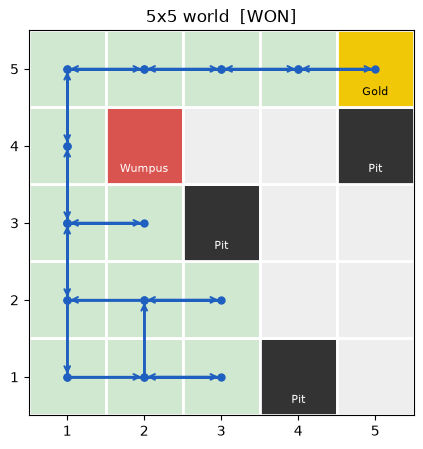

In [25]:
# Demo 4 - another hand-made world (5x5)
world5 = make_world(5, wumpus=(2, 4), pits={(4, 1), (3, 3), (5, 4)}, gold=(5, 5))
show_world(world5)
agent5 = make_agent(world5, verbose=False)
run_agent(agent5)
show_final(agent5)
plot_path(agent5, "5x5 world")

In [26]:
# Testing - 300 random 4x4 worlds. Soundness: the agent must NEVER die.
def random_world(n=4, pit_prob=0.2):
    cells = [(x, y) for x in range(1, n + 1) for y in range(1, n + 1) if (x, y) != (1, 1)]
    pits = {c for c in cells if random.random() < pit_prob}
    free = [c for c in cells if c not in pits]
    wumpus = random.choice(free)
    gold = random.choice([c for c in free if c != wumpus])
    return make_world(n, wumpus, pits, gold)

random.seed(7)
stats = {"WON": 0, "STUCK": 0, "DIED": 0}
for _ in range(300):
    stats[run_agent(make_agent(random_world(), verbose=False))["status"]] += 1
print("Results over 300 random worlds:", stats)
print("Deaths:", stats["DIED"], " <- must be 0, the agent only moves to PROVEN-safe cells")
assert stats["DIED"] == 0

Results over 300 random worlds: {'WON': 103, 'STUCK': 197, 'DIED': 0}
Deaths: 0  <- must be 0, the agent only moves to PROVEN-safe cells
